# 05 Uplift modelling: who does the SMS move?

**Project question.** With a limited marketing budget, which customers should receive an SMS so that it creates the most additional purchases?

**This notebook.** Notebook 04 showed that the SMS effect differs between clients, one variable at a time. Here, models combine all features to estimate each client's *uplift*: the change in purchase probability caused by the SMS. They are compared on how well their ranking finds the clients the SMS affects most. All work uses the five training folds; the test set is left for notebook 06.

**Summary.** A model trained on clients' past shopping can pick out who the SMS actually moves: among the 10% it ranks highest, the SMS adds about 10 extra buyers per 100 messages, three times the average and twelve times more than among the clients most likely to buy anyway. These clients tend to be older, newer to the loyalty card, shop less often and redeem points. The gain is concentrated in that top tenth, and the final check on untouched data comes in notebook 06.

**Research question.** Can data from before the SMS rank clients by how much the SMS changes their purchase, better than ranking them by purchase probability?

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from x5uplift import plotting as P
from x5uplift.config import FEATURE_GROUPS_PATH, PROPENSITY_PATH, SEED, SEGMENTS_PATH, UPLIFT_PATH, UPLIFT_SCORES_PATH
from x5uplift.modeling import load_experiment, model_matrix
from x5uplift.uplift import (ClassTransformation, SLearner, TLearner, UpliftForest, XLearner, bootstrap_metrics,
                             calibration_by_decile, cross_fit_uplift, ranking, summarize, uplift_curve, curve_metrics)
from x5uplift.experiment import diff_in_means

pd.set_option("display.width", 140)
import causalml.inference.tree  # noqa: F401  causalml changes the matplotlib style on import; set_style() below restores ours
P.set_style()

/Users/alper/Desktop/x5-uplift-targeting/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Failed to import duecredit due to No module named 'duecredit'


## 1. Data

The five training folds, both groups. Every model is evaluated with cross fitting: each client's uplift comes from a model that did not see that client.

In [2]:
exp = load_experiment().merge(pd.read_parquet(PROPENSITY_PATH), on="client_id", validate="one_to_one")
train = exp[exp["fold"] >= 0].reset_index(drop=True)          # fold -1 is the untouched test set
feature_cols = [c for cols in json.loads(FEATURE_GROUPS_PATH.read_text()).values() for c in cols]
X = model_matrix(train, feature_cols)
t, y, fold = (train[c].to_numpy() for c in ["treatment_flg", "target", "fold"])

pd.Series({"clients": len(train), "features": X.shape[1],
           "share with SMS": round(t.mean(), 4), "purchase rate": round(y.mean(), 4)})

clients           140027.0000
features              54.0000
share with SMS         0.4998
purchase rate          0.6199
dtype: float64

## 2. Four meta learners

All four use the gradient boosting model of notebook 03 with the same settings, so differences come from the uplift method.

* **S-learner:** one model with the SMS flag as a feature; uplift = its prediction with the SMS minus without.
* **T-learner:** one model per group; uplift = the SMS model's prediction minus the control model's.
* **X-learner:** starts from the T-learner, then models each client's imputed effect (own outcome minus the other group's prediction) and averages the two resulting models.
* **Class transformation:** a new label that is 1 for SMS buyers and control non-buyers. Because half of the clients got the SMS, 2 × P(label = 1) − 1 equals the uplift, so one classifier targets the uplift directly.

In [3]:
learners = {"S-learner": SLearner, "T-learner": TLearner, "X-learner": XLearner,
            "Class transformation": ClassTransformation}
scores = {}
for name, Learner in learners.items():
    start = time.time()
    scores[name] = cross_fit_uplift(lambda: Learner(seed=SEED), X, t, y, fold)
    print(f"{name}: {time.time() - start:.0f} s")

pd.DataFrame(scores).describe().T.drop(columns="count").mul(100).round(2)   # predicted uplift, in points

S-learner: 30 s
T-learner: 30 s
X-learner: 50 s
Class transformation: 9 s


,mean,std,min,25%,50%,75%,max
S-learner,2.63,2.84,-9.54,0.82,1.99,3.62,52.84
T-learner,3.24,5.45,-32.61,0.13,2.58,5.84,61.38
X-learner,3.25,2.77,-6.77,1.70,2.65,4.04,49.99
Class transformation,3.32,3.08,-14.39,1.81,2.99,4.30,52.36


## 3. Uplift forest

The four meta learners model purchases and derive the uplift from them. Here, where habit predicts purchases well and the SMS effect is small, much of their capacity goes to the habit. An uplift forest (causalml) instead chooses each split by how much the SMS effect differs between the two sides, so all of its capacity goes to the effect. causalml does not accept missing values, so they are filled with the median plus an indicator column, as for logistic regression in notebook 03.

In [4]:
cached = pd.read_parquet(UPLIFT_SCORES_PATH) if UPLIFT_SCORES_PATH.exists() else None
if cached is not None and "Uplift forest" in cached and cached["client_id"].equals(train["client_id"]):
    scores["Uplift forest"] = cached["Uplift forest"].to_numpy()
    print("Uplift forest: loaded from", UPLIFT_SCORES_PATH.name)
else:
    start = time.time()
    scores["Uplift forest"] = cross_fit_uplift(lambda: UpliftForest(seed=SEED), X, t, y, fold)
    print(f"Uplift forest: {(time.time() - start) / 60:.0f} min")

pd.DataFrame({"client_id": train["client_id"], **scores}).to_parquet(UPLIFT_SCORES_PATH, index=False)
pd.Series(scores["Uplift forest"]).describe().drop("count").mul(100).round(2)

Uplift forest: loaded from uplift_scores.parquet


mean     3.41
std      1.85
min     -1.11
25%      2.46
50%      3.06
75%      3.82
max     28.28
dtype: float64

## 4. Which ranking finds the clients the SMS moves?

Each model ranks clients by predicted uplift. Two references are added: a **random** ranking (no targeting) and the **purchase probability** of notebook 03, which ranks likely buyers first, a common default.

* **Uplift curve:** if the top share of the ranking gets the SMS, how many extra purchases does that create, per client of the whole group? It is estimated inside the top share as the SMS purchase rate minus the control purchase rate, times the share contacted. At 100% every ranking reaches the average effect.
* **AUUC** (area under the uplift curve): how far the curve lies above the random ranking, averaged over all budgets, in extra purchases per 100 clients. Random targeting scores 0.
* **Uplift in the top 10%, 20%, 30%:** the effect of the SMS among the clients a budget of that size would contact, in percentage points.

Intervals come from 300 bootstrap resamples of the clients; all rankings share the same resamples, so differences between them are paired.

In [5]:
compare = {**scores,
           "Purchase probability": train["p_buy_without_sms"].to_numpy(),
           "Random": np.random.default_rng(SEED).random(len(train))}
boot = bootstrap_metrics(y, t, compare, n_boot=300)

def fmt(s):
    """Estimate [95% interval] in points, one row per ranking."""
    s = s * 100
    text = s["estimate"].map("{:.2f}".format) + " [" + s["ci_low"].map("{:.2f}".format) + ", " + s["ci_high"].map("{:.2f}".format) + "]"
    return text.unstack("metric").loc[list(compare)]

fmt(summarize(boot))

metric,auuc,uplift_top_10,uplift_top_20,uplift_top_30
model,,,,
S-learner,"0.54 [0.40, 0.68]","10.57 [9.02, 11.92]","8.40 [7.36, 9.65]","6.43 [5.59, 7.47]"
T-learner,"0.39 [0.24, 0.54]","8.51 [6.69, 10.02]","6.06 [4.84, 7.25]","5.08 [4.06, 5.98]"
X-learner,"0.60 [0.46, 0.75]","10.02 [8.25, 11.51]","6.97 [5.71, 8.08]","6.02 [5.04, 6.99]"
Class transformation,"0.46 [0.31, 0.59]","7.76 [6.06, 9.26]","6.26 [5.01, 7.28]","5.72 [4.74, 6.67]"
Uplift forest,"0.54 [0.40, 0.67]","9.15 [7.50, 10.78]","7.13 [6.02, 8.25]","5.90 [4.93, 6.80]"
Purchase probability,"-0.39 [-0.51, -0.27]","0.83 [0.07, 1.54]","1.34 [0.74, 1.98]","1.76 [1.16, 2.39]"
Random,"-0.08 [-0.23, 0.05]","3.03 [1.47, 4.57]","3.02 [1.95, 4.10]","3.02 [2.13, 3.88]"


In [6]:
fmt(summarize(boot, reference="Purchase probability")).drop(index="Purchase probability")

metric,auuc,uplift_top_10,uplift_top_20,uplift_top_30
model,,,,
S-learner,"0.93 [0.73, 1.14]","9.74 [7.91, 11.34]","7.06 [5.96, 8.47]","4.67 [3.65, 5.84]"
T-learner,"0.77 [0.56, 0.98]","7.67 [5.90, 9.38]","4.72 [3.29, 6.13]","3.31 [2.24, 4.41]"
X-learner,"0.99 [0.76, 1.21]","9.19 [7.25, 10.83]","5.63 [4.33, 6.97]","4.26 [3.15, 5.36]"
Class transformation,"0.84 [0.62, 1.03]","6.92 [5.09, 8.44]","4.92 [3.56, 5.97]","3.95 [2.82, 4.99]"
Uplift forest,"0.93 [0.73, 1.14]","8.32 [6.53, 9.96]","5.79 [4.62, 7.06]","4.14 [3.09, 5.25]"
Random,"0.31 [0.13, 0.51]","2.20 [0.36, 3.92]","1.68 [0.43, 2.92]","1.26 [0.30, 2.16]"


In [7]:
fmt(summarize(boot, reference="X-learner")).drop(index=["X-learner", "Random"])

metric,auuc,uplift_top_10,uplift_top_20,uplift_top_30
model,,,,
S-learner,"-0.06 [-0.18, 0.05]","0.55 [-0.82, 1.95]","1.43 [0.35, 2.59]","0.41 [-0.29, 1.22]"
T-learner,"-0.22 [-0.37, -0.07]","-1.51 [-3.11, 0.30]","-0.90 [-2.09, 0.25]","-0.94 [-1.74, -0.13]"
Class transformation,"-0.15 [-0.30, -0.00]","-2.26 [-4.08, -0.54]","-0.71 [-2.00, 0.48]","-0.31 [-1.26, 0.56]"
Uplift forest,"-0.06 [-0.17, 0.05]","-0.87 [-2.49, 0.62]","0.16 [-0.90, 1.18]","-0.12 [-0.87, 0.66]"
Purchase probability,"-0.99 [-1.21, -0.76]","-9.19 [-10.83, -7.25]","-5.63 [-6.97, -4.33]","-4.26 [-5.36, -3.15]"


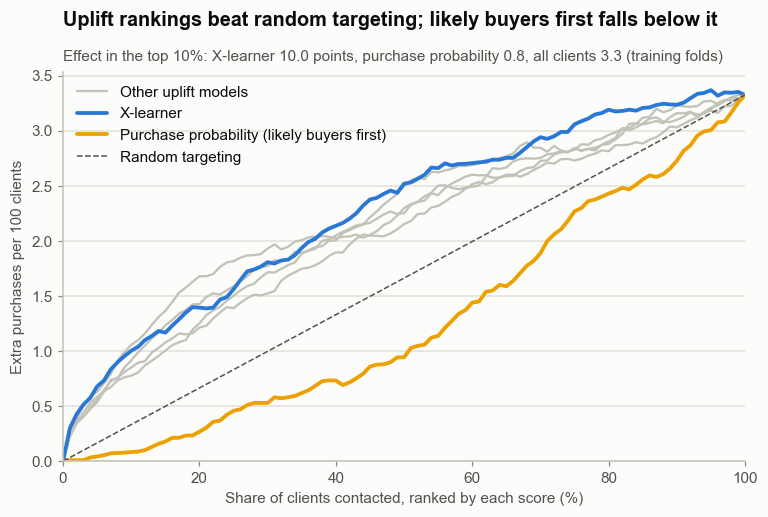

In [8]:
best = "X-learner"
curves = {name: 100 * uplift_curve(y, t, ranking(s)) for name, s in compare.items() if name != "Random"}
ate = curves[best][-1]
pct = np.linspace(0, 100, 101)

fig, ax = plt.subplots(figsize=(8, 4.6))
others = [name for name in curves if name not in (best, "Purchase probability")]
for i, name in enumerate(others):
    ax.plot(pct, curves[name], color=P.AXIS, linewidth=1.5, label="Other uplift models" if i == 0 else None)
ax.plot(pct, curves[best], color=P.BLUE, linewidth=2.5, label=best)
ax.plot(pct, curves["Purchase probability"], color=P.YELLOW, linewidth=2.5, label="Purchase probability (likely buyers first)")
ax.plot([0, 100], [0, curves[best][-1]], color=P.INK_2, linewidth=1, linestyle="--", label="Random targeting")
ax.set(xlim=(0, 100), ylim=(0, None), xlabel="Share of clients contacted, ranked by each score (%)",
       ylabel="Extra purchases per 100 clients")
ax.legend(loc="upper left")
top10 = {name: c[10] * 10 for name, c in curves.items()}          # effect among the top 10%, in points
P.titles(ax, "Uplift rankings beat random targeting; likely buyers first falls below it",
         f"Effect in the top 10%: {best} {top10[best]:.1f} points, purchase probability "
         f"{top10['Purchase probability']:.1f}, all clients {curves[best][-1]:.1f} (training folds)")
P.save(fig, "05_uplift_curves")

## 5. Are the results stable across random seeds?

The intervals above reflect which clients happen to be in the sample, not the randomness inside the models (early stopping splits, tree sampling). Each model is refitted with other seeds: the four meta learners with five seeds, the slower forest with three. If a model's AUUC moves a lot between seeds, small differences between models are not meaningful.

In [9]:
SEEDS = [SEED + i for i in range(5)]
runs_path = UPLIFT_SCORES_PATH.with_name("uplift_scores_by_seed.parquet")
runs = pd.read_parquet(runs_path) if runs_path.exists() else pd.DataFrame({"client_id": train["client_id"]})
assert runs["client_id"].equals(train["client_id"])

for name, Learner in {**learners, "Uplift forest": UpliftForest}.items():
    for s in (SEEDS[:3] if name == "Uplift forest" else SEEDS):
        col = f"{name} | {s}"
        if col not in runs:
            start = time.time()
            runs[col] = scores[name] if s == SEED else cross_fit_uplift(lambda: Learner(seed=s), X, t, y, fold)
            runs.to_parquet(runs_path, index=False)      # saved after every run
            print(f"{col}: {time.time() - start:.0f} s")

per_seed = pd.DataFrame([{"model": c.split(" | ")[0], "seed": int(c.split(" | ")[1]),
                          **curve_metrics(uplift_curve(y, t, ranking(runs[c])))}
                         for c in runs.columns if " | " in c])
(per_seed.drop(columns="seed").groupby("model", sort=False).agg(["mean", "std", "min", "max"]) * 100).round(2)

auuc                   uplift_top_10                    uplift_top_20                   uplift_top_30              \
                      mean   std   min   max          mean   std   min    max          mean   std   min   max          mean   std   min   
model                                                                                                                                     
S-learner             0.59  0.04  0.54  0.64         10.27  0.77  8.96  11.00          7.82  0.40  7.29  8.40          6.25  0.15  6.08   
T-learner             0.44  0.05  0.38  0.50          8.21  0.31  7.73   8.51          6.22  0.27  5.82  6.47          5.24  0.26  4.90   
X-learner             0.60  0.01  0.59  0.61         10.24  0.26  9.98  10.54          7.40  0.32  6.97  7.69          6.06  0.27  5.62   
Class transformation  0.41  0.04  0.36  0.46          7.80  0.29  7.34   8.09          6.35  0.20  6.08  6.62          5.49  0.13  5.39   
Uplift forest         0.51  0.03  0.49  0.54          9.38  0.41  9.13   9.85          7.10  0.27  6.82  7.35          5.70  0.24  5.43   

                            
                       max  
model                       
S-learner             6.43  
T-learner             5.53  
X-learner             6.33  
Class transformation  5.72  
Uplift forest         5.90

## 6. Does the predicted uplift match the observed effect?

The X-learner is kept for notebook 06: its AUUC equals the S-learner's on average (0.60 against 0.59 across seeds) but varies much less between seeds (standard deviation 0.01 against 0.04, and 0.3 against 0.8 points for the effect in the top 10%). The uplift forest, built to target the effect directly, did not do better here than the meta learners.

A good ranking is not enough for a budget decision: notebook 06 also uses the *size* of the predicted uplift. Clients are grouped into deciles of predicted uplift, and in each decile the average prediction is compared with the effect actually observed between its SMS and control clients.

In [10]:
cal = calibration_by_decile(y, t, scores[best])[["predicted", "effect", "ci_low", "ci_high"]] * 100   # decile 1 = highest
cal.round(2)

,predicted,effect,ci_low,ci_high
1,9.07,10.02,8.38,11.67
2,5.11,3.92,2.26,5.57
3,4.06,4.09,2.44,5.74
4,3.38,2.97,1.34,4.61
5,2.87,3.89,2.28,5.50
6,2.46,1.61,0.04,3.19
7,2.08,2.20,0.66,3.74
8,1.70,2.67,1.18,4.16
9,1.29,0.22,-1.21,1.65
10,0.48,0.81,-0.74,2.35


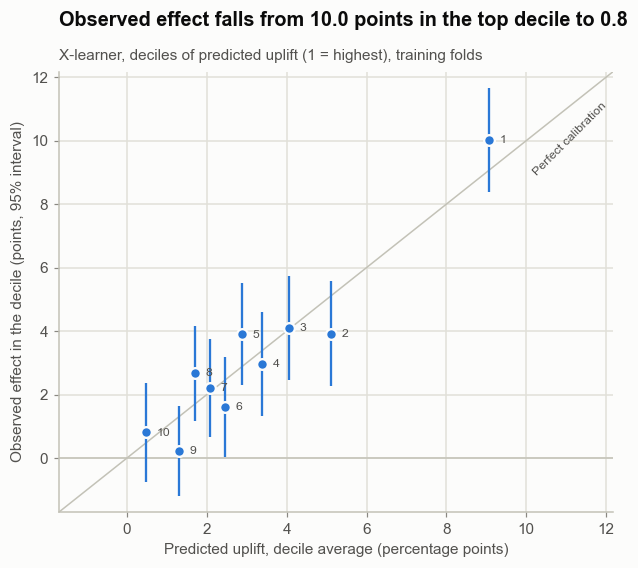

In [11]:
lo = min(cal["ci_low"].min(), cal["predicted"].min(), 0) - 0.5
hi = max(cal["ci_high"].max(), cal["predicted"].max()) + 0.5

fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.plot([lo, hi], [lo, hi], color=P.AXIS, linewidth=1)
ax.text(hi - 0.3, hi - 0.9, "Perfect calibration", rotation=45, fontsize=8, color=P.INK_2,
        ha="right", va="top", rotation_mode="anchor")
ax.axhline(0, color=P.AXIS, linewidth=1)
ax.errorbar(cal["predicted"], cal["effect"], yerr=[cal["effect"] - cal["ci_low"], cal["ci_high"] - cal["effect"]],
            fmt="o", color=P.BLUE, markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=1.5)
for d, r in cal.iterrows():
    ax.annotate(str(d), (r["predicted"], r["effect"]), xytext=(7, 0), textcoords="offset points",
                fontsize=8, color=P.INK_2, va="center")
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Predicted uplift, decile average (percentage points)",
       ylabel="Observed effect in the decile (points, 95% interval)")
ax.grid(axis="x", visible=True)
P.titles(ax, f"Observed effect falls from {cal['effect'].iloc[0]:.1f} points in the top decile to {cal['effect'].iloc[-1]:.1f}",
         f"{best}, deciles of predicted uplift (1 = highest), training folds")
P.save(fig, "05_calibration")

The X-learner is well calibrated: in all ten deciles the observed effect's 95% interval contains the predicted uplift, with no systematic over or under prediction. The signal is concentrated at the top: about 10 points in the first decile, 1.6 to 4.1 points in deciles 2 to 8, under 1 point in the last two. No decile shows a negative effect.

## 7. Who are the clients the model expects to move most?

A description, not a cause: the top decile of predicted uplift is compared with all clients on information from before the SMS. Notebook 04 found larger effects among older clients, point redeemers and clients unlikely to buy anyway; this checks whether the model learned the same pattern from all features at once.

In [12]:
labels = {"p_buy_without_sms": "Purchase probability without SMS", "age": "Age", "n_baskets_recent": "Visits, last 30 days",
          "days_since_last_purchase": "Days since last purchase", "avg_basket_spend": "Average basket spend",
          "n_distinct_products": "Distinct products bought", "share_baskets_points_spent": "Baskets with points spent",
          "share_own_brand": "Own brand share", "share_alcohol": "Alcohol share", "days_since_card_issue": "Days since card issue"}
decile = pd.qcut(pd.Series(-scores[best]).rank(method="first"), 10, labels=range(1, 11)).to_numpy()
group = np.select([decile == 1, decile == 10], ["Top decile", "Bottom decile"], "Deciles 2 to 9")

feats = train[list(labels)]
smd = ((feats[decile == 1].mean() - feats.mean()) / feats.std()).rename(labels).sort_values()
pd.concat([feats.groupby(group).median().T.rename(index=labels)[["Top decile", "Deciles 2 to 9", "Bottom decile"]].round(2),
           smd.rename("top_vs_all_smd").round(2)], axis=1)

,Top decile,Deciles 2 to 9,Bottom decile,top_vs_all_smd
Purchase probability without SMS,0.405852,0.635117,0.738483,-0.77
Age,57.0,45.0,36.0,0.5
"Visits, last 30 days",2.0,5.0,6.0,-0.54
Days since last purchase,8.366192,4.318588,3.472407,0.4
Average basket spend,274.6,397.375,488.604667,-0.28
Distinct products bought,27.0,64.0,107.0,-0.73
Baskets with points spent,0.1,0.04,0.036585,0.7
Own brand share,0.078093,0.081119,0.08243,0.08
Alcohol share,0.0,0.0,0.019428,-0.07
Days since card issue,282.0,492.0,586.0,-0.63


In [13]:
segment = pd.read_parquet(SEGMENTS_PATH).set_index("client_id").loc[train["client_id"], "segment_name"].to_numpy()
(pd.crosstab(segment, group, normalize="columns").mul(100).round(1)
   [["Top decile", "Deciles 2 to 9", "Bottom decile"]].sort_values("Top decile", ascending=False))

col_0,Top decile,Deciles 2 to 9,Bottom decile
row_0,,,
Regular small baskets,35.6,23.9,11.4
Occasional shoppers,26.7,15.2,13.4
Point redeemers,18.1,3.8,2.8
Big basket shoppers,8.1,23.6,30.0
Alcohol and own brand buyers,6.3,6.6,6.4
Daily top-up shoppers,4.3,25.6,34.5
Express point collectors,0.9,1.2,1.5


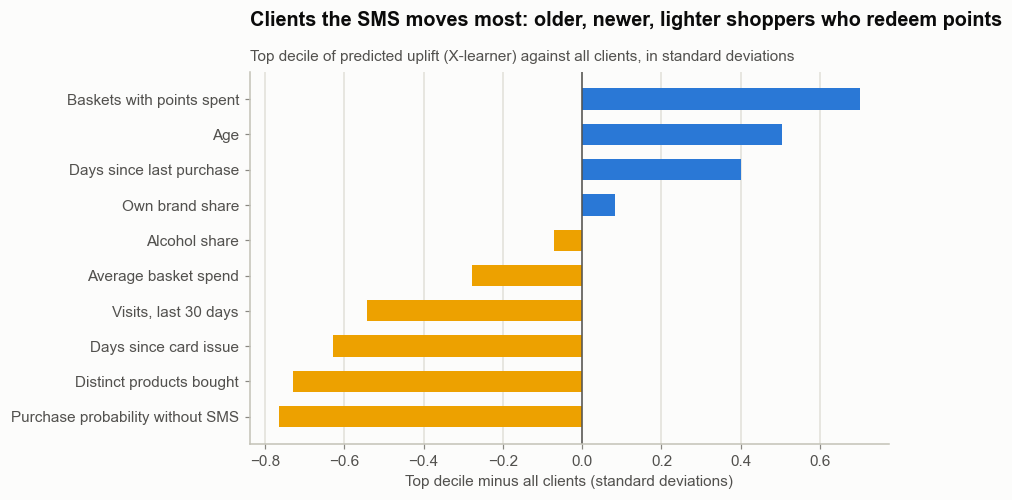

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(smd.index, smd.values, color=np.where(smd.values > 0, P.BLUE, P.YELLOW), height=0.6)
ax.axvline(0, color=P.INK_2, linewidth=1)
ax.set_xlabel("Top decile minus all clients (standard deviations)")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
P.titles(ax, "Clients the SMS moves most: older, newer, lighter shoppers who redeem points",
        f"Top decile of predicted uplift ({best}) against all clients, in standard deviations")
P.save(fig, "05_top_decile_profile")

## 8. Four client types, as predicted tendencies

Marketing often splits clients into four types: **persuadables** (buy only with the SMS), **sure things** (buy either way), **lost causes** (buy in neither case) and **sleeping dogs** (buy only without the SMS). The type of a single client can never be observed, because each client either got the SMS or not. Here the types are only *predicted tendencies*: the probability of buying without an SMS comes from notebook 03, the probability with an SMS adds the X-learner's predicted uplift, and each is compared with 0.5. Within each predicted type, the observed effect between its SMS and control clients shows whether the label means anything.

In [15]:
p0 = train["p_buy_without_sms"].to_numpy()
p1 = np.clip(p0 + scores[best], 0, 1)
types = np.select([(p1 >= 0.5) & (p0 < 0.5), (p1 >= 0.5) & (p0 >= 0.5), (p1 < 0.5) & (p0 < 0.5)],
                  ["Persuadable", "Sure thing", "Lost cause"], "Sleeping dog")

rows = {}
for name in ["Persuadable", "Sure thing", "Lost cause", "Sleeping dog"]:
    m = types == name
    rows[name] = {"clients": int(m.sum()), "share_pct": 100 * m.mean()}
    if m.sum() >= 200:     # too few clients for an effect estimate otherwise
        rows[name] |= {"p_buy_without_sms": 100 * p0[m].mean(), "predicted_uplift": 100 * scores[best][m].mean(),
                       **{k: 100 * v for k, v in diff_in_means(y[m], t[m]).items() if k in ("effect", "ci_low", "ci_high")}}
pd.DataFrame(rows).T.round(2)

,clients,share_pct,p_buy_without_sms,predicted_uplift,effect,ci_low,ci_high
Persuadable,7321.0,5.23,46.14,6.90,8.80,6.52,11.08
Sure thing,88776.0,63.40,75.22,2.64,2.50,1.95,3.06
Lost cause,43910.0,31.36,32.76,3.88,4.11,3.22,5.00
Sleeping dog,20.0,0.01,NaN,NaN,NaN,NaN,NaN


The labels carry information: predicted persuadables (5% of clients) show an observed effect of 8.8 points [6.5, 11.1], about 2.7 times the average, and in each type the observed effect is close to the predicted uplift. But they hold only about one seventh of the extra purchases (clients × effect); most come from "sure things" (2.5 points on 63% of clients) and "lost causes" (4.1 points on 31%). The 0.5 threshold that defines the types has nothing to do with where the SMS works, so "contact only persuadables" would miss most of the gain. Only 20 clients are predicted sleeping dogs, too few to estimate an effect. Targeting is therefore done by ranking on predicted uplift, not by these labels.

## 9. Predictions for the test set

The X-learner is refitted once on all training folds and predicts the test set. Test outcomes are not looked at here; they are used only in notebook 06. The saved file holds one uplift per experiment client: out of fold for the training folds, from this final model for the test set, as for the purchase probability in notebook 03.

In [16]:
test = exp[exp["fold"] < 0].reset_index(drop=True)
X_test = model_matrix(test, feature_cols)
assert list(X_test.columns) == list(X.columns)
final = XLearner(seed=SEED).fit(X, t, y)

out = pd.concat([
    pd.DataFrame({"client_id": train["client_id"], "uplift": scores[best], "part": "training folds"}),
    pd.DataFrame({"client_id": test["client_id"], "uplift": final.predict(X_test), "part": "test set"}),
])
out.drop(columns="part").to_parquet(UPLIFT_PATH, index=False)
out.groupby("part")["uplift"].describe().drop(columns="count").mul(100).round(2)

,mean,std,min,25%,50%,75%,max
part,,,,,,,
test set,3.29,2.53,-3.82,1.85,2.76,4.05,39.81
training folds,3.25,2.77,-6.77,1.70,2.65,4.04,49.99


Both parts have a similar distribution (mean 3.25 and 3.29 points); the final model, fitted on more data, gives slightly narrower predictions (standard deviation 2.53 against 2.77).

## Conclusion

**Answer.** Yes. Ranking clients by the X-learner's predicted uplift finds the clients the SMS moves: in the top 10% the SMS raises the purchase rate by 10.0 points [8.3, 11.5], against 3.0 for a random 10% and 0.8 for the 10% most likely to buy anyway. Over all budgets, the uplift ranking beats the purchase probability ranking by 0.99 extra purchases per 100 clients [0.76, 1.21], while the purchase probability ranking does worse than random.

**What we learned**
* All five uplift methods beat both references. The X-learner and the S-learner lead (AUUC 0.60 and 0.59 across seeds); the X-learner was kept because it varies much less between seeds (standard deviation 0.01 against 0.04).
* The uplift forest, which targets the effect directly, did not do better than the meta learners (AUUC 0.51). The T-learner, which subtracts two noisy models, was the weakest.
* Model randomness is small next to sampling uncertainty (seed standard deviations 0.01 to 0.05, bootstrap half width about 0.14).
* The X-learner is well calibrated: in all ten deciles the observed effect's interval contains the predicted uplift. The signal is concentrated in the top decile (about 10 points); deciles 2 to 8 lie between 1.6 and 4.1 points.
* The clients the model expects to move most are older (median 57 against 45), less likely to buy anyway (41% against 64%), visit less often, have newer cards and redeem points more often. This matches notebook 04 and adds card tenure.
* The four client types are only predicted tendencies. Predicted persuadables respond most (8.8 points) but hold only about one seventh of the extra purchases, so targeting uses the uplift ranking, not the labels.

**What remains open**
* The model was chosen among five on the same training folds, which flatters the chosen one slightly. Its unbiased performance comes from the untouched test set in notebook 06.
* Beyond the top decile the gain over random targeting shrinks quickly, so the value of targeting depends on the budget. Notebook 06 measures this with costs and margins.
* The profile of the top decile is descriptive; it does not show that age, card tenure or point use cause a stronger response.

**Next step.** Notebook 06 compares four policies on the test set (contact everyone, contact at random, contact likely buyers, contact by predicted uplift) as incremental purchases and incremental profit by budget, with intervals and a sensitivity analysis for contact cost and margin.